# Train and evaluate a model for classifying composition clusters and archetypes based on cell type fractions

In [1]:
import scanpy as sc
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import celltypist
import time

from sklearn.metrics import accuracy_score, balanced_accuracy_score
from sklearn.metrics import classification_report

%config InlineBackend.figure_format = 'retina'

In this notebook we demonstrate how to train an archetype model based on an scRNA-seq dataset using CellTypist and how to evaluate its performance in a held-out test set to understand the robustness of individual archetypes and tissue composition subtypes.

We use a reference sample-level AnnData of the Cardinal PBMC atlas (we use synthetic data based on original cell composition distributions as original sample-level data requires biobank access).

In [2]:
# Load reference sample-level Cardinal PBMC object
adata = archetypist.cardinal_synthetic_reference()
#adata = sc.read_h5ad('cardinal_synthetic_reference.h5ad')

In [3]:
adata

AnnData object with n_obs × n_vars = 3000 × 79
    obs: 'composition_cluster', 'archetype', 'synthetic', 'reference_group_n'
    uns: 'archetype_colors', 'composition_cluster_colors', 'synthetic_reference'
    obsm: 'X_draw_graph_fa'

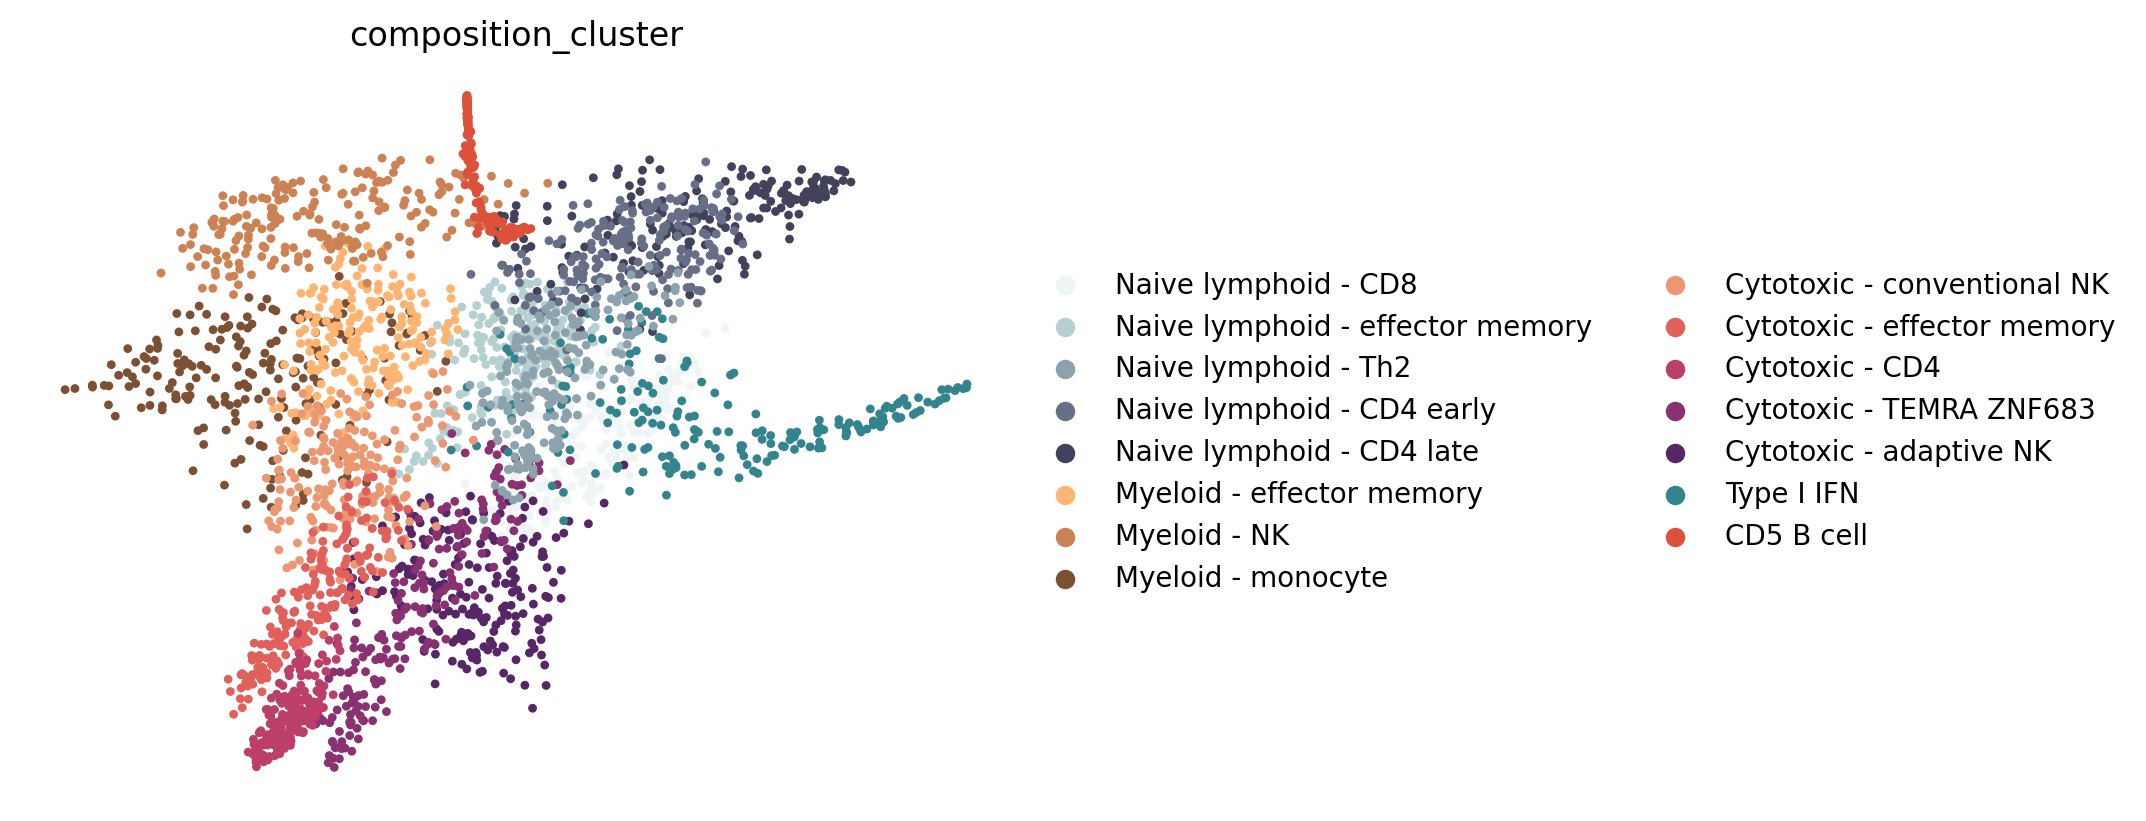

In [4]:
sc.pl.embedding(adata, basis='X_draw_graph_fa', color='composition_cluster', frameon=False)

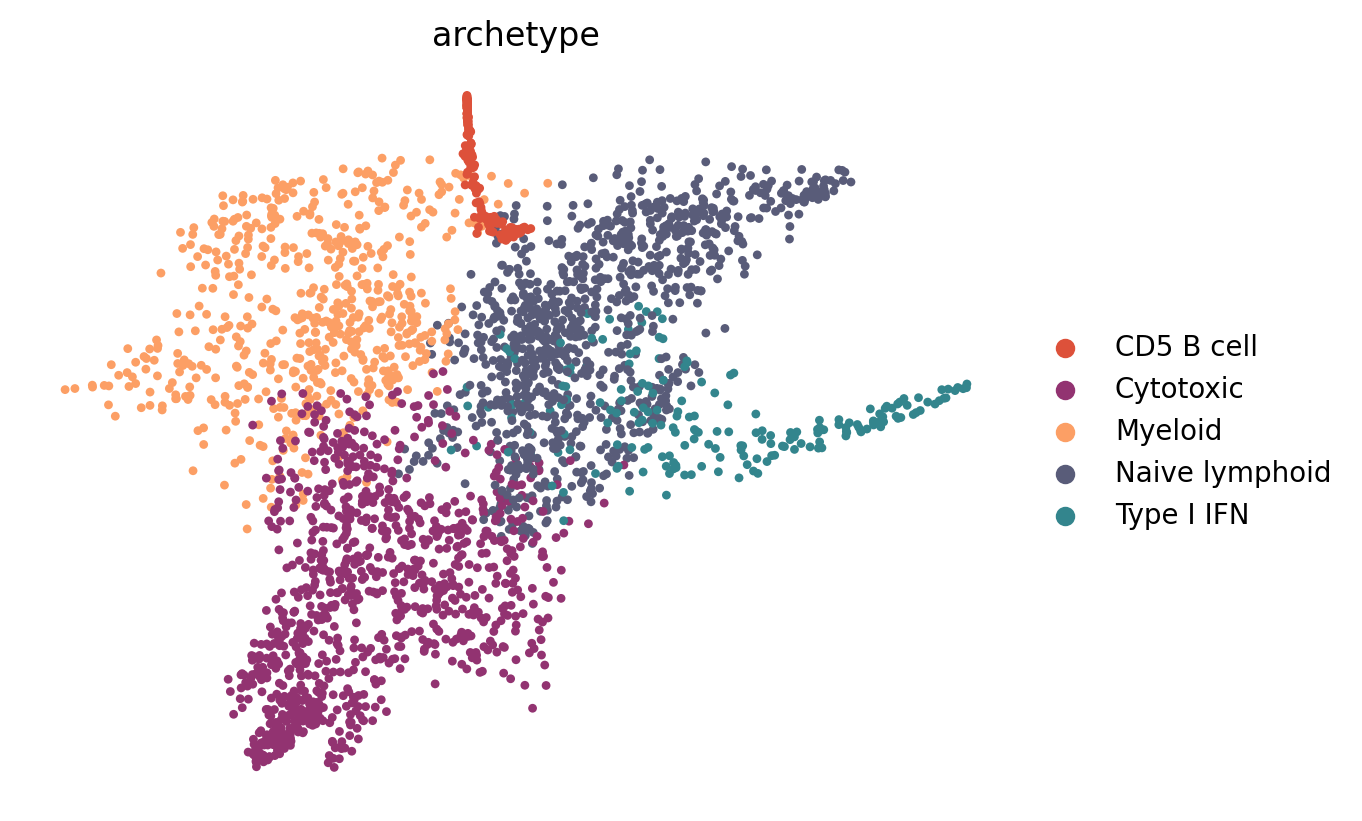

In [5]:
sc.pl.embedding(adata, basis='X_draw_graph_fa', color='archetype', frameon=False)

## Train model

We train a model to classify composition clusters (more fine-grained than archetypes) using CellTypist, ran on cell type fraction data.

In [6]:
#  Replace composition_cluster with archetype to train a model for archetypes
t_start = time.time()
model = celltypist.train(adata, 'composition_cluster', check_expression = False, n_jobs = 10, max_iter = 100)
t_end = time.time()
print(f"Time elapsed: {(t_end - t_start)/60} minutes")
# model.write('cardinal_comp_cluster_model.pkl')

🍳 Preparing data before training
🔬 Input data has 3000 cells and 79 genes
⚖️ Scaling input data
🏋️ Training data using logistic regression
✅ Model training done!


Time elapsed: 0.15122936169306436 minutes


In [7]:
t_start = time.time()
predictions = celltypist.annotate(adata, model = model, majority_voting = True)
t_end = time.time()

⚠️ Warning: invalid expression matrix, expect ALL genes and log1p normalized expression to 10000 counts per cell. The prediction result may not be accurate
🔬 Input data has 3000 cells and 79 genes
🔗 Matching reference genes in the model
🧬 79 features used for prediction
⚖️ Scaling input data
🖋️ Predicting labels
✅ Prediction done!
👀 Can not detect a neighborhood graph, will construct one before the over-clustering
⛓️ Over-clustering input data with resolution set to 5
🗳️ Majority voting the predictions
✅ Majority voting done!


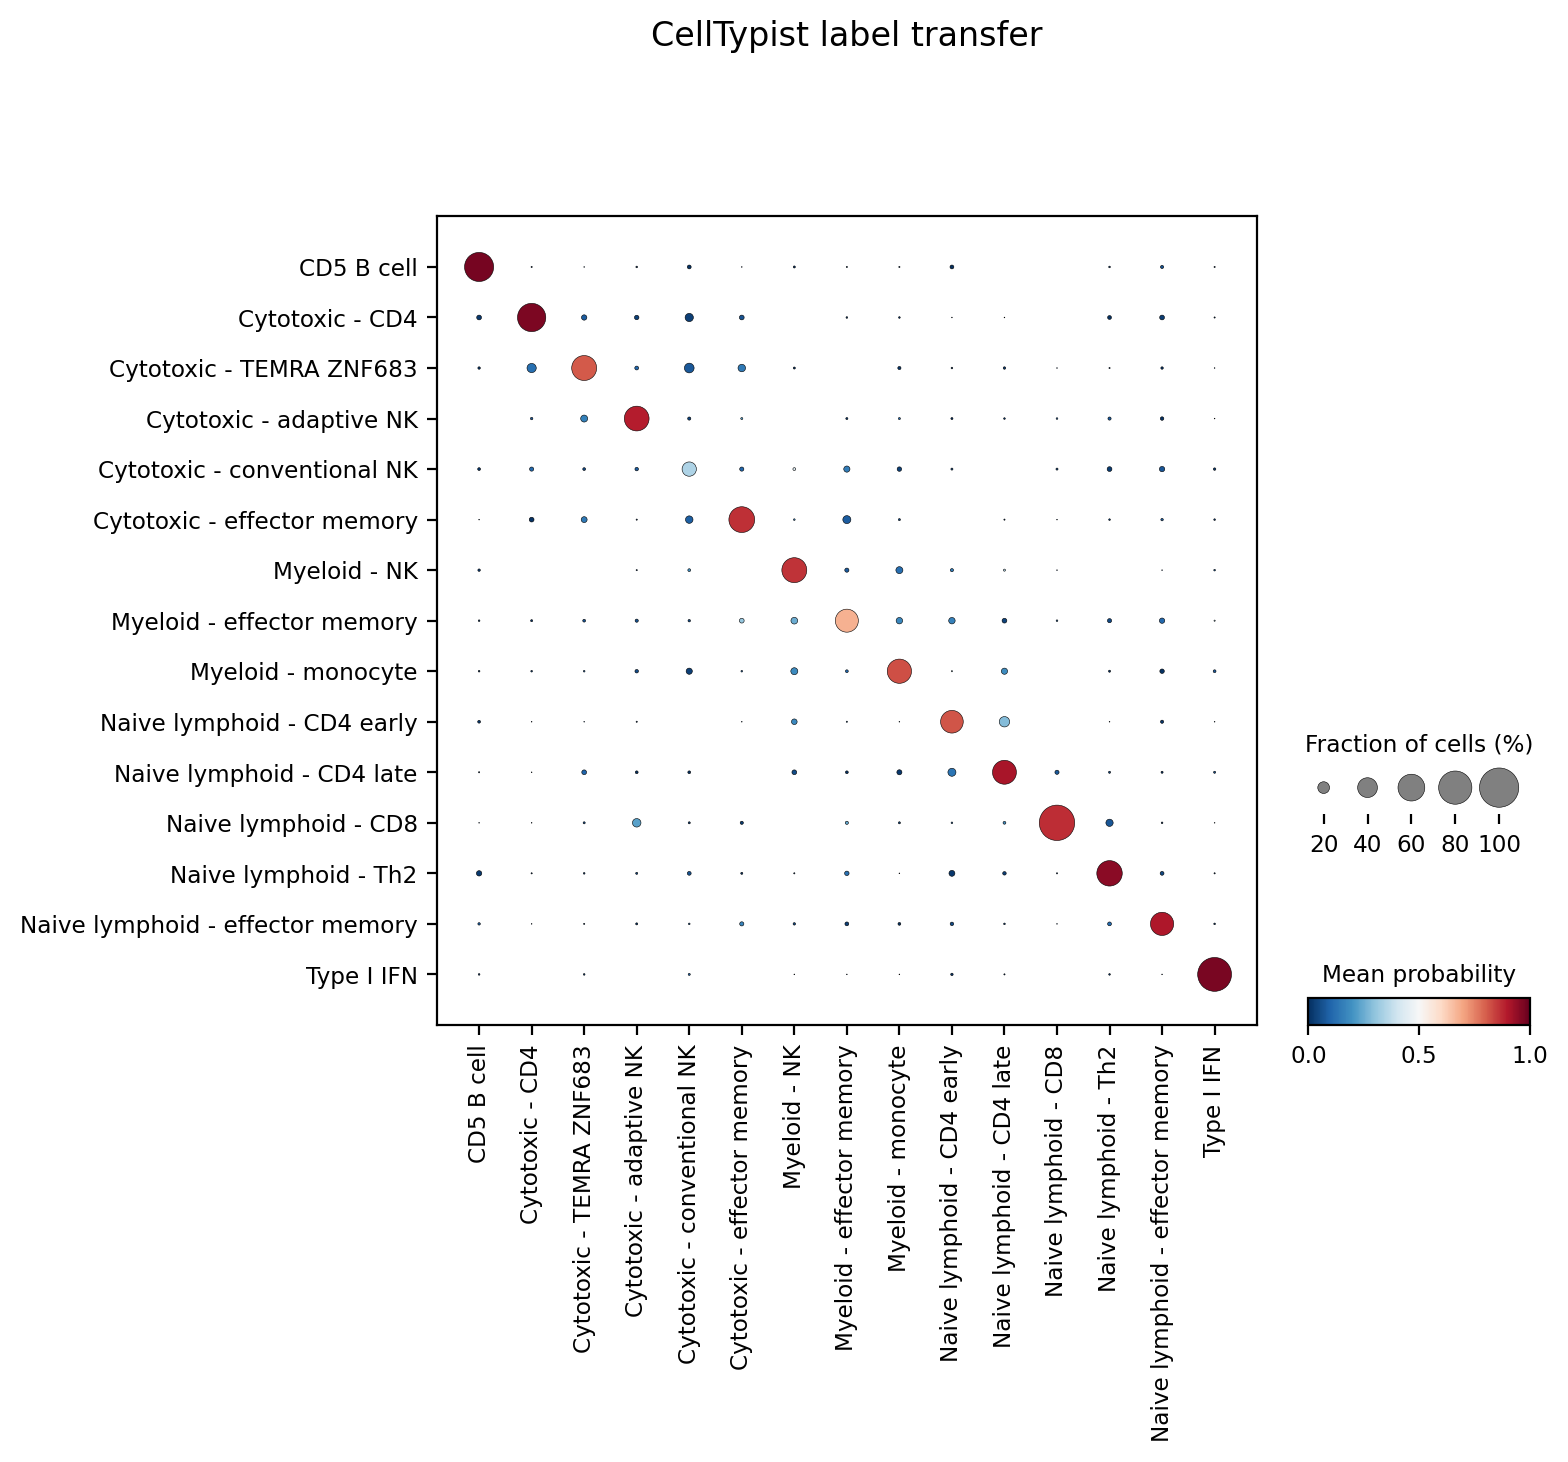

In [10]:
celltypist.dotplot(predictions, use_as_reference = 'composition_cluster', use_as_prediction = 'majority_voting')
adata = predictions.to_adata()

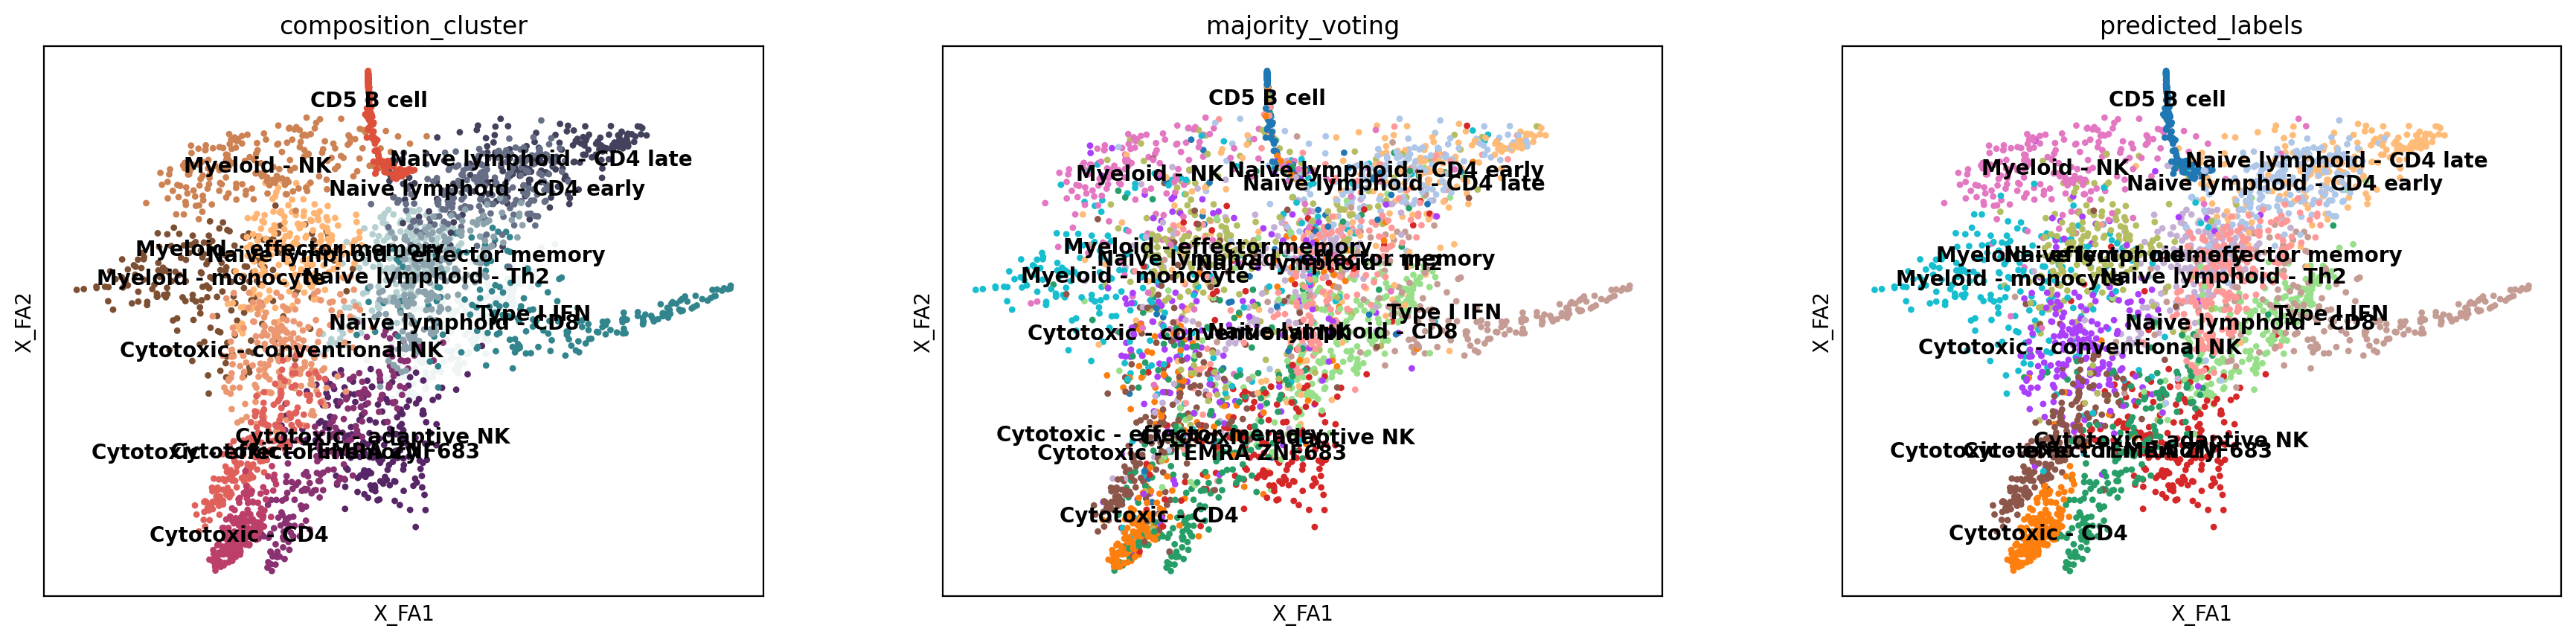

In [11]:
sc.pl.embedding(adata, basis = 'X_draw_graph_fa', color = ['composition_cluster', 'predicted_labels', 'majority_voting'], legend_loc = 'on data')

We take a look at accurary metrics.

In [12]:
# 1. Prepare labels

# keep only samples with all labels present
df = adata2.obs[["composition_cluster", "predicted_labels", "majority_voting"]].dropna()

y_true = df["composition_cluster"]
y_pred = df["predicted_labels"]
y_mv   = df["majority_voting"]

# 2. Overall accuracy
print("Predicted_labels accuracy:", accuracy_score(y_true, y_pred))
print("Majority_voting accuracy:", accuracy_score(y_true, y_mv))

print("Predicted_labels balanced accuracy:", balanced_accuracy_score(y_true, y_pred))
print("Majority_voting balanced accuracy:", balanced_accuracy_score(y_true, y_mv))

Predicted_labels accuracy: 0.9036666666666666
Majority_voting accuracy: 0.5686666666666667
Predicted_labels balanced accuracy: 0.9036666666666666
Majority_voting balanced accuracy: 0.5686666666666668


In [13]:
# 3. Per–cell type performance
print("Predicted_labels\n")
print(classification_report(y_true, y_pred))

print("\nMajority_voting\n")
print(classification_report(y_true, y_mv))

Predicted_labels

                                  precision    recall  f1-score   support

                      CD5 B cell       1.00      0.98      0.99       200
                 Cytotoxic - CD4       0.94      0.99      0.97       200
        Cytotoxic - TEMRA ZNF683       0.88      0.87      0.87       200
         Cytotoxic - adaptive NK       0.93      0.86      0.89       200
     Cytotoxic - conventional NK       0.82      0.80      0.81       200
     Cytotoxic - effector memory       0.90      0.90      0.90       200
                    Myeloid - NK       0.89      0.89      0.89       200
       Myeloid - effector memory       0.80      0.79      0.80       200
              Myeloid - monocyte       0.84      0.84      0.84       200
      Naive lymphoid - CD4 early       0.89      0.86      0.88       200
       Naive lymphoid - CD4 late       0.91      0.94      0.92       200
            Naive lymphoid - CD8       0.91      0.96      0.93       200
            Naive l

## Evaluate performance using data split into train and test sets

Here we repeat model training but using data split into train and test sets. This allows us to evaluate the performance of the model on unseen data. Additionally, by defining which composition clusters are easy to classify correctly, we understand better which ones are more robust and clearly distinguishable. 

In [14]:
# Split an AnnData object into train and test sets

def split_adata(adata, test_frac=0.2, seed=0):
    np.random.seed(seed)

    n = adata.n_obs
    idx = np.random.permutation(n)

    n_test = int(n * test_frac)
    test_idx = idx[:n_test]
    train_idx = idx[n_test:]

    adata_train = adata[train_idx].copy()
    adata_test = adata[test_idx].copy()

    return adata_train, adata_test


adata_train, adata_test = split_adata(adata, test_frac=0.2)

We first train a model on the training set. We also test model performance on the training set for later comparison with test set.

In [15]:
t_start = time.time()
model_train = celltypist.train(adata_train, 'composition_cluster', check_expression = False, n_jobs = 10, max_iter = 100)
t_end = time.time()
print(f"Time elapsed: {(t_end - t_start)/60} minutes")

🍳 Preparing data before training
🔬 Input data has 2400 cells and 79 genes
⚖️ Scaling input data
🏋️ Training data using logistic regression
✅ Model training done!


Time elapsed: 0.024716965357462563 minutes


In [16]:
# Predict on train set
t_start = time.time()
predictions = celltypist.annotate(adata_train, model = model_train, majority_voting = True)
t_end = time.time()

⚠️ Warning: invalid expression matrix, expect ALL genes and log1p normalized expression to 10000 counts per cell. The prediction result may not be accurate
🔬 Input data has 2400 cells and 79 genes
🔗 Matching reference genes in the model
🧬 79 features used for prediction
⚖️ Scaling input data
🖋️ Predicting labels
✅ Prediction done!
👀 Detected a neighborhood graph in the input object, will run over-clustering on the basis of it
⛓️ Over-clustering input data with resolution set to 5
🗳️ Majority voting the predictions
✅ Majority voting done!


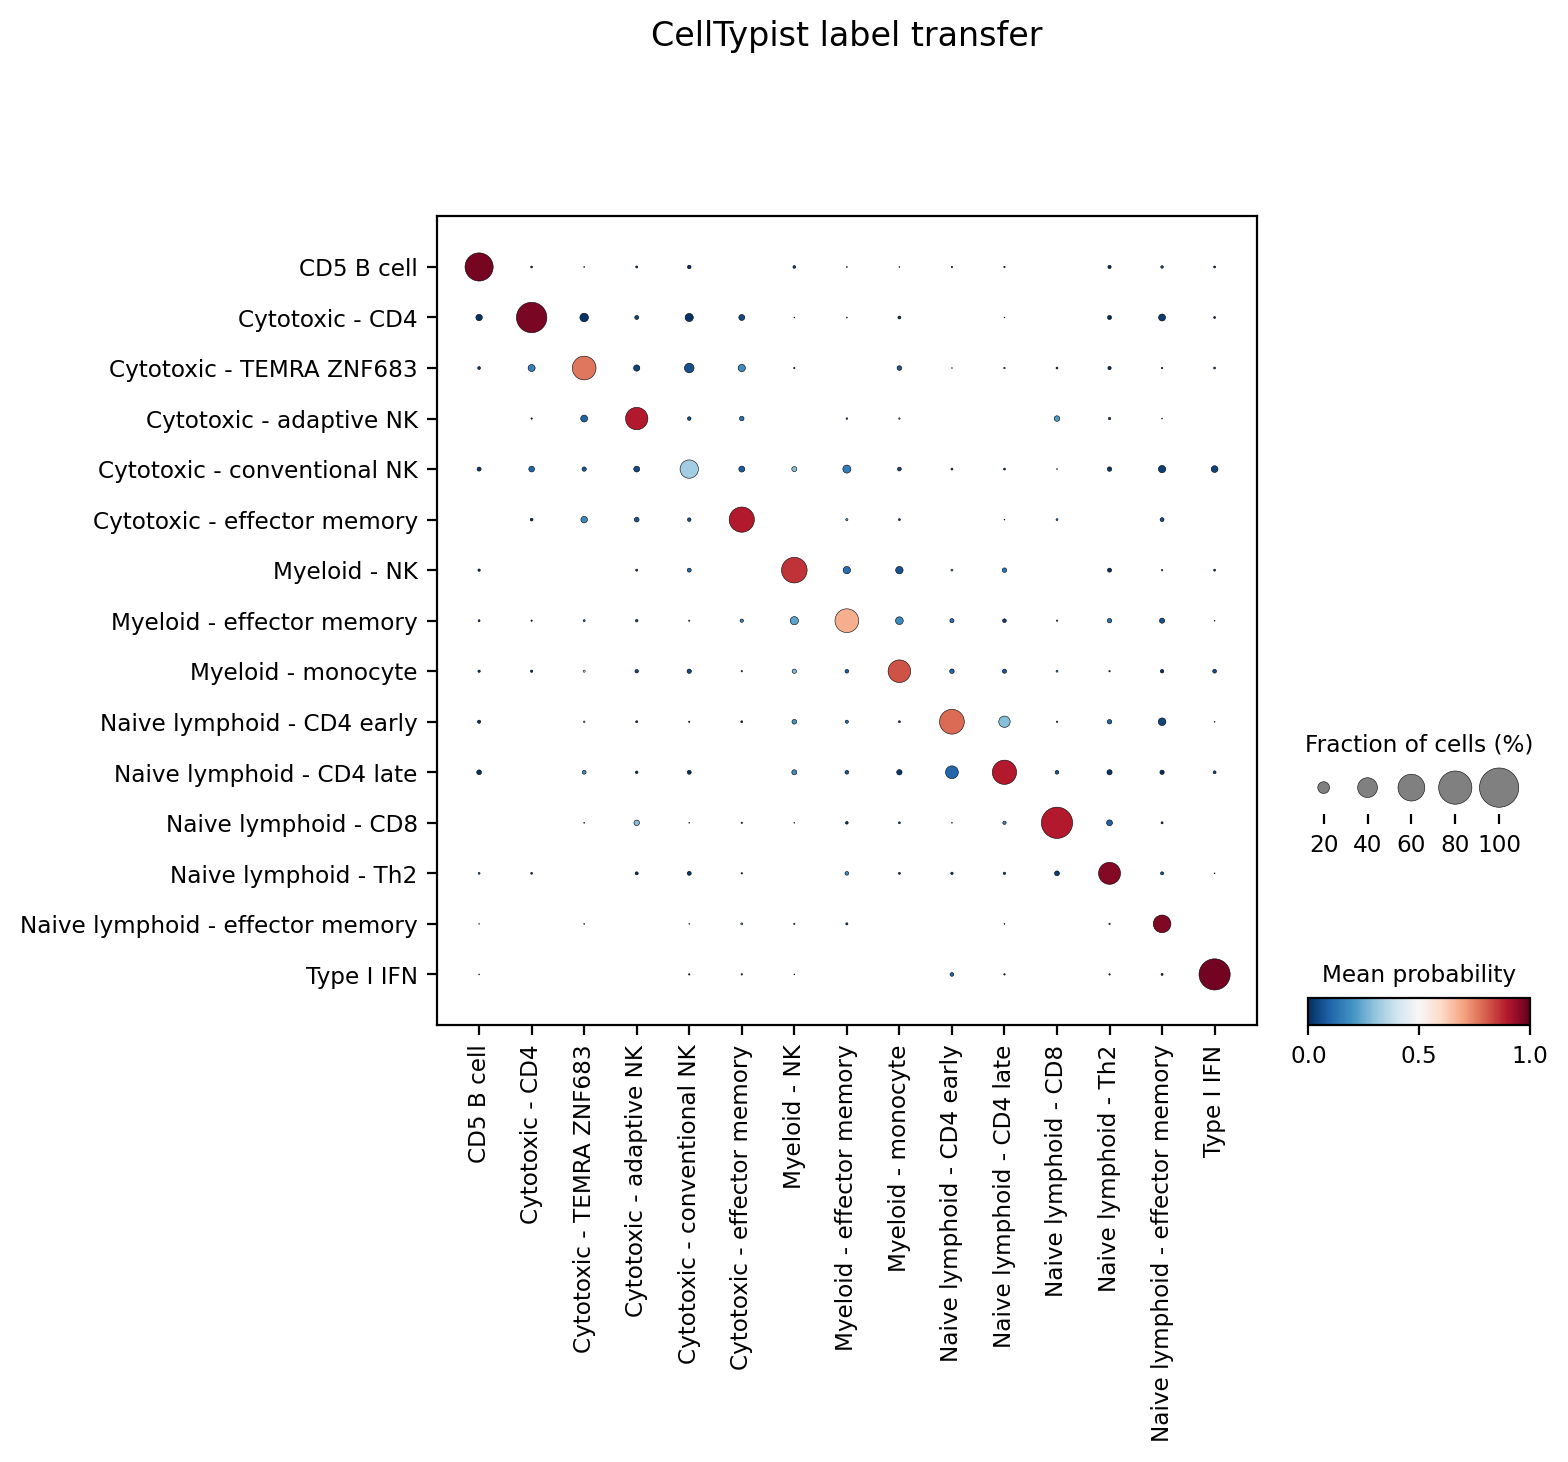

In [17]:
celltypist.dotplot(predictions, use_as_reference = 'composition_cluster', use_as_prediction = 'majority_voting')
adata_train = predictions.to_adata()

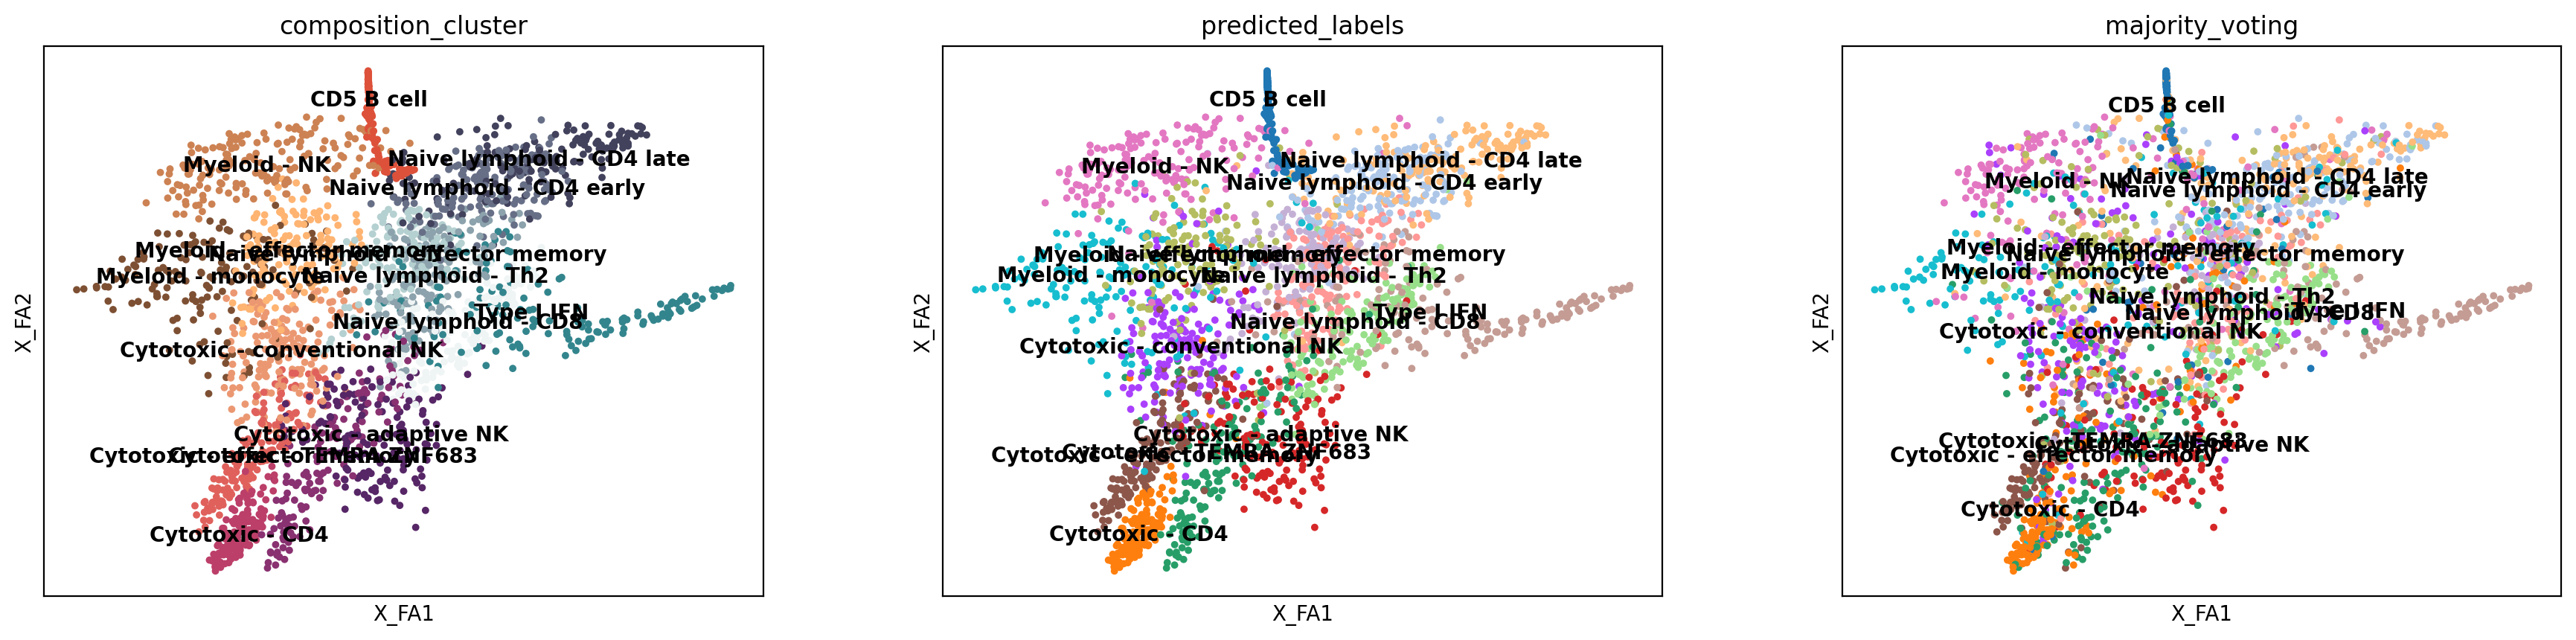

In [19]:
sc.pl.embedding(adata_train, basis = 'X_draw_graph_fa', color = ['composition_cluster', 'predicted_labels', 'majority_voting'], legend_loc = 'on data')

In [21]:
# 1. Prepare labels

# keep only samples with all labels present
df_train = adata_train.obs[["composition_cluster", "predicted_labels", "majority_voting"]].dropna()

y_true_train = df_train["composition_cluster"]
y_pred_train = df_train["predicted_labels"]
y_mv_train   = df_train["majority_voting"]

# 2. Overall accuracy
print("Predicted_labels accuracy:", accuracy_score(y_true_train, y_pred_train))
print("Majority_voting accuracy:", accuracy_score(y_true_train, y_mv_train))

print("Predicted_labels balanced accuracy:", balanced_accuracy_score(y_true_train, y_pred_train))
print("Majority_voting balanced accuracy:", balanced_accuracy_score(y_true_train, y_mv_train))

Predicted_labels accuracy: 0.9204166666666667
Majority_voting accuracy: 0.5441666666666667
Predicted_labels balanced accuracy: 0.9192353405767215
Majority_voting balanced accuracy: 0.5426409422117768


In [22]:
# 3. Per–cell type performance
print("Predicted_labels\n")
print(classification_report(y_true_train, y_pred_train))

print("\nMajority_voting\n")
print(classification_report(y_true_train, y_mv_train))

Predicted_labels

                                  precision    recall  f1-score   support

                      CD5 B cell       1.00      0.99      1.00       167
                 Cytotoxic - CD4       0.95      0.99      0.97       169
        Cytotoxic - TEMRA ZNF683       0.87      0.88      0.87       153
         Cytotoxic - adaptive NK       0.91      0.90      0.91       151
     Cytotoxic - conventional NK       0.87      0.82      0.84       171
     Cytotoxic - effector memory       0.93      0.94      0.93       161
                    Myeloid - NK       0.89      0.90      0.90       170
       Myeloid - effector memory       0.81      0.81      0.81       141
              Myeloid - monocyte       0.84      0.87      0.86       157
      Naive lymphoid - CD4 early       0.91      0.89      0.90       161
       Naive lymphoid - CD4 late       0.93      0.94      0.94       162
            Naive lymphoid - CD8       0.95      0.96      0.95       163
            Naive l

We then use the model to predict on the test set.

In [23]:
# Predict on test set
t_start = time.time()
predictions = celltypist.annotate(adata_test, model = model_train, majority_voting = True)
t_end = time.time()

⚠️ Warning: invalid expression matrix, expect ALL genes and log1p normalized expression to 10000 counts per cell. The prediction result may not be accurate
🔬 Input data has 600 cells and 79 genes
🔗 Matching reference genes in the model
🧬 79 features used for prediction
⚖️ Scaling input data
🖋️ Predicting labels
✅ Prediction done!
👀 Detected a neighborhood graph in the input object, will run over-clustering on the basis of it
⛓️ Over-clustering input data with resolution set to 5
🗳️ Majority voting the predictions
✅ Majority voting done!


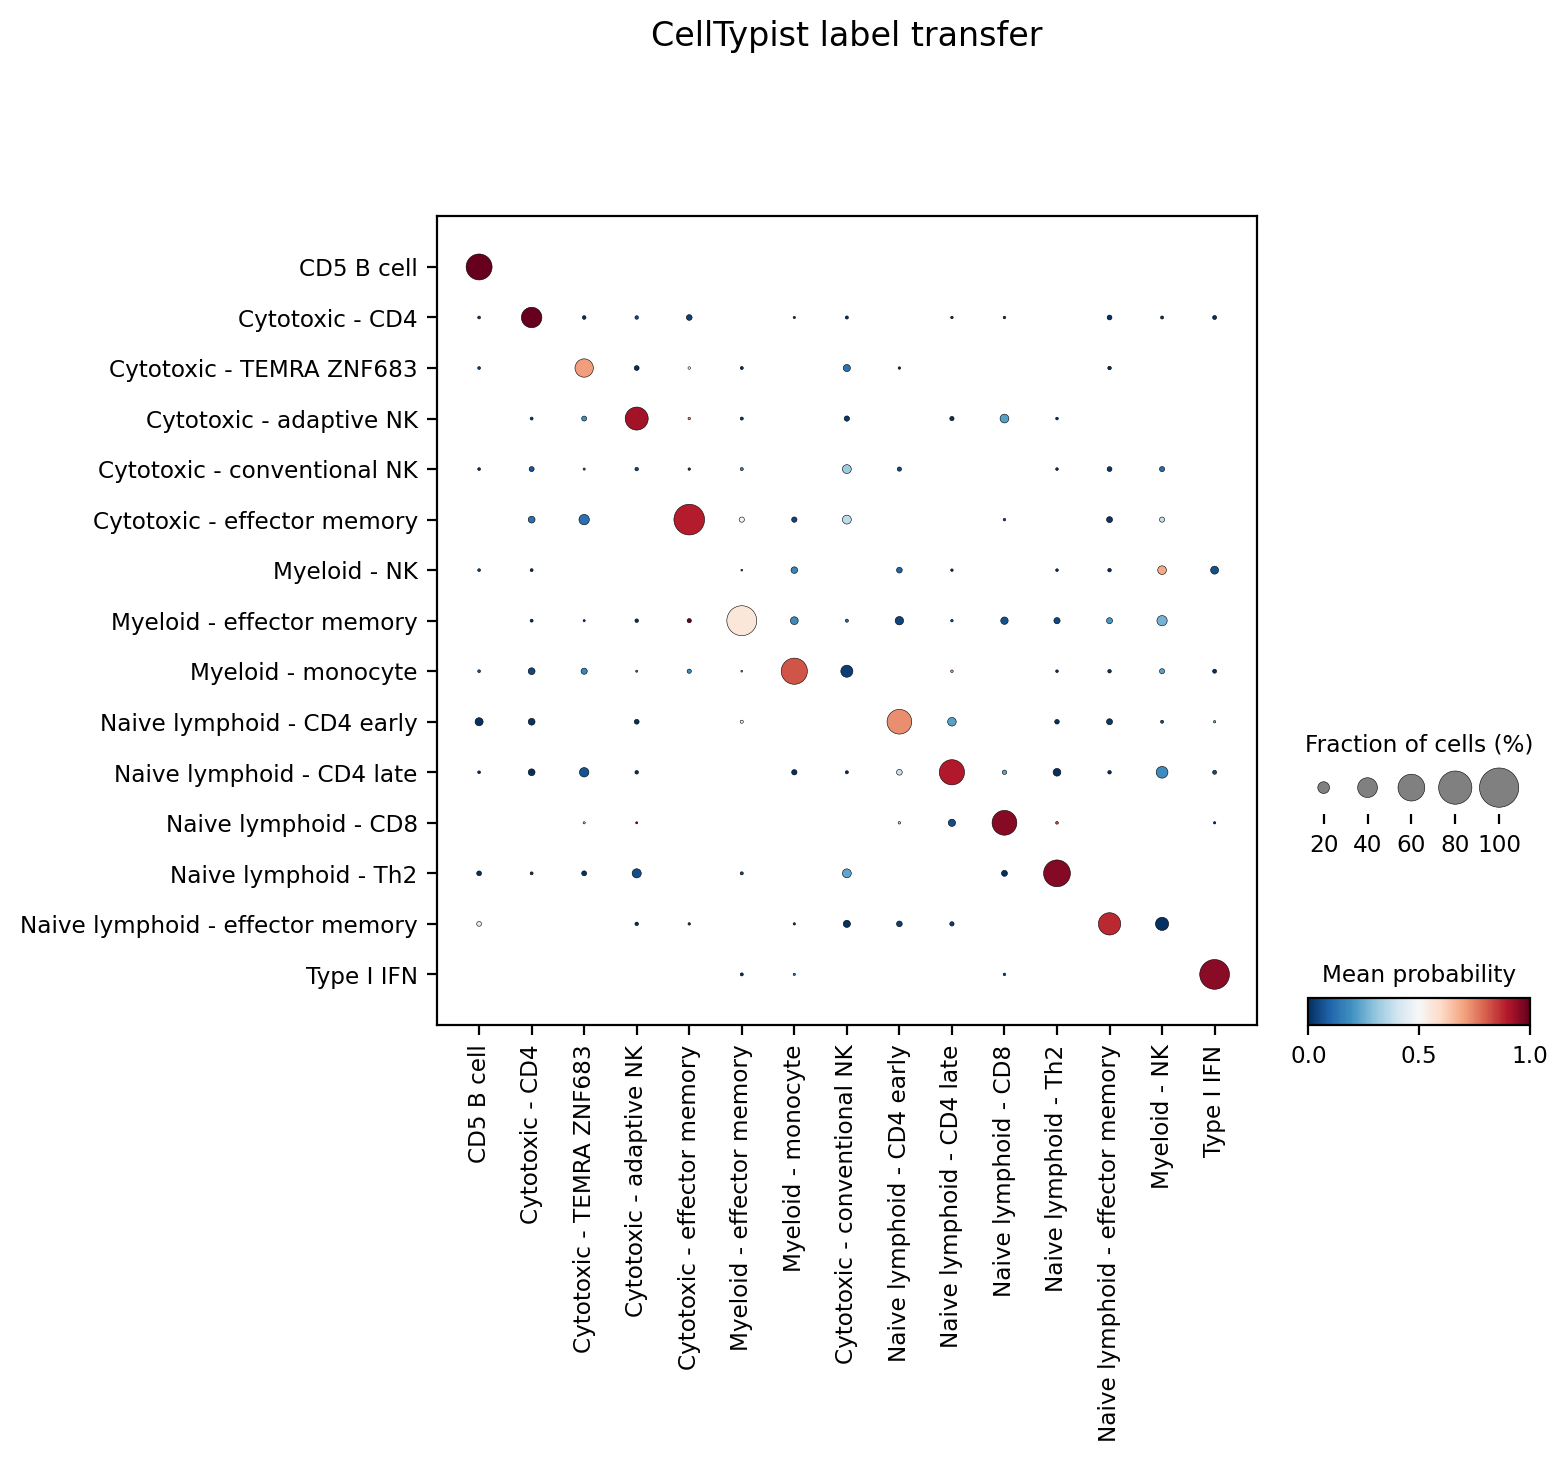

In [24]:
celltypist.dotplot(predictions, use_as_reference = 'composition_cluster', use_as_prediction = 'majority_voting')
adata_test = predictions.to_adata()

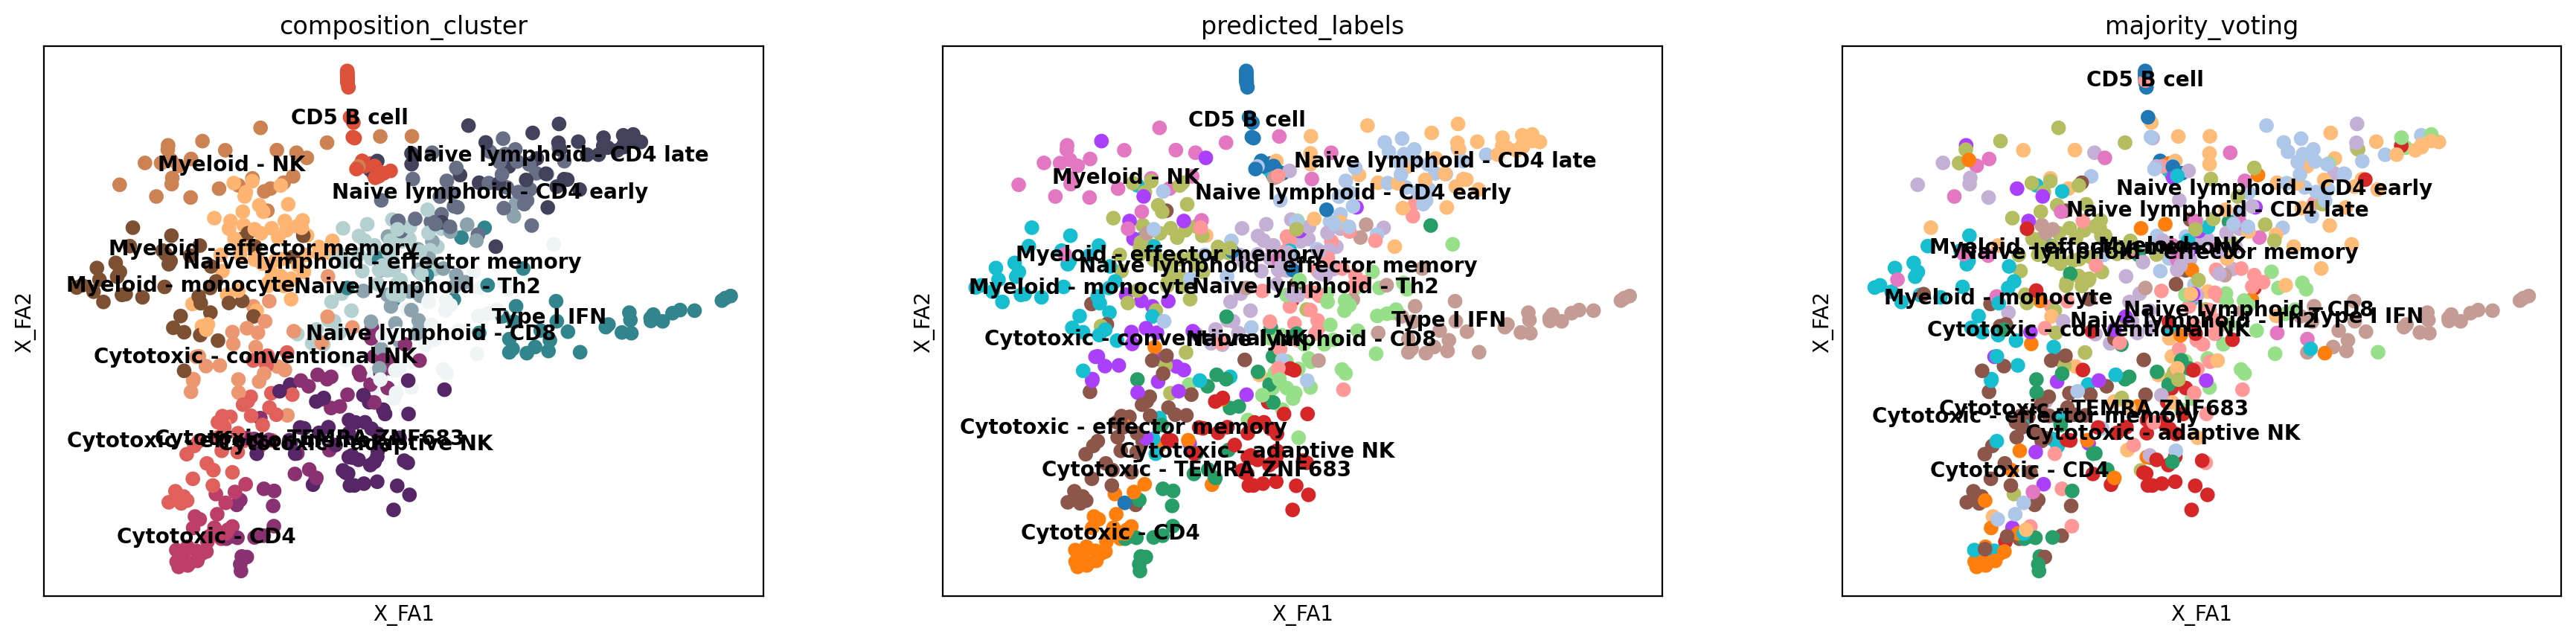

In [25]:
sc.pl.embedding(adata_test, basis = 'X_draw_graph_fa', color = ['composition_cluster', 'predicted_labels', 'majority_voting'], legend_loc = 'on data')

In [26]:
# 1. Prepare labels

# keep only samples with all labels present
df_test = adata_test.obs[["composition_cluster", "predicted_labels", "majority_voting"]].dropna()

y_true_test = df_test["composition_cluster"]
y_pred_test = df_test["predicted_labels"]
y_mv_test   = df_test["majority_voting"]

# 2. Overall accuracy
print("Predicted_labels accuracy:", accuracy_score(y_true_test, y_pred_test))
print("Majority_voting accuracy:", accuracy_score(y_true_test, y_mv_test))

print("Predicted_labels balanced accuracy:", balanced_accuracy_score(y_true_test, y_pred_test))
print("Majority_voting balanced accuracy:", balanced_accuracy_score(y_true_test, y_mv_test))

Predicted_labels accuracy: 0.805
Majority_voting accuracy: 0.5166666666666667
Predicted_labels balanced accuracy: 0.8111801759289676
Majority_voting balanced accuracy: 0.5002421168574106


In [27]:
# 3. Per–cell type performance
print("Predicted_labels\n")
print(classification_report(y_true_test, y_pred_test))

print("\nMajority_voting\n")
print(classification_report(y_true_test, y_mv_test))

Predicted_labels

                                  precision    recall  f1-score   support

                      CD5 B cell       0.88      0.91      0.90        33
                 Cytotoxic - CD4       0.83      0.97      0.90        31
        Cytotoxic - TEMRA ZNF683       0.86      0.64      0.73        47
         Cytotoxic - adaptive NK       0.88      0.73      0.80        49
     Cytotoxic - conventional NK       0.56      0.62      0.59        29
     Cytotoxic - effector memory       0.77      0.85      0.80        39
                    Myeloid - NK       0.73      0.73      0.73        30
       Myeloid - effector memory       0.82      0.69      0.75        59
              Myeloid - monocyte       0.80      0.84      0.82        43
      Naive lymphoid - CD4 early       0.67      0.77      0.71        39
       Naive lymphoid - CD4 late       0.85      0.92      0.89        38
            Naive lymphoid - CD8       0.73      0.89      0.80        37
            Naive l

Finally, we compare the prediction metrics across the train and test sets.

In [28]:
# Plot two sklearn classification reports as side-by-side heatmaps

def plot_classification_reports(
    y_true1,
    y_pred1,
    y_true2,
    y_pred2,
    title1="Model 1",
    title2="Model 2",
    drop_summary=True,
    figsize=(10, 5),
    cmap="viridis",
    annot=True,
    vmin=None,
    vmax=None,
):

    def order_index(idx):
        idx = list(idx)

        start_groups = ["Naive lymphoid", "Myeloid", "Cytotoxic"]
        end_groups = ["Type I IFN", "CD5 B cell"]

        def sort_key(label):
            for i, group in enumerate(start_groups):
                if str(label).startswith(group):
                    return (0, i, str(label))
            if label in end_groups:
                return (2, end_groups.index(label), str(label))
            return (1, str(label))

        return sorted(idx, key=sort_key)

    rep1 = classification_report(y_true1, y_pred1, output_dict=True)
    rep2 = classification_report(y_true2, y_pred2, output_dict=True)

    df1 = pd.DataFrame(rep1).T
    df2 = pd.DataFrame(rep2).T

    cols = ["precision", "recall", "f1-score"]
    df1 = df1[cols]
    df2 = df2[cols]

    if drop_summary:
        drop_rows = ["accuracy", "macro avg", "weighted avg"]
        df1 = df1.drop(index=[x for x in drop_rows if x in df1.index], errors="ignore")
        df2 = df2.drop(index=[x for x in drop_rows if x in df2.index], errors="ignore")

    ordered_idx = order_index(df1.index)
    ordered_idx = [x for x in ordered_idx if x in df2.index]

    df1 = df1.loc[ordered_idx]
    df2 = df2.loc[ordered_idx]

    # Shared scale
    if vmin is None or vmax is None:
        vmin = np.nanmin([df1.values.min(), df2.values.min()])
        vmax = np.nanmax([df1.values.max(), df2.values.max()])

    # Layout: tighter spacing
    fig = plt.figure(figsize=figsize)
    gs = fig.add_gridspec(1, 3, width_ratios=[1, 1, 0.04], wspace=0.05)

    ax1 = fig.add_subplot(gs[0, 0])
    ax2 = fig.add_subplot(gs[0, 1])
    cax = fig.add_subplot(gs[0, 2])

    sns.heatmap(
        df1, annot=annot, fmt=".2f", cmap=cmap,
        ax=ax1, vmin=vmin, vmax=vmax, cbar=False
    )
    ax1.set_title(title1)
    ax1.set_xlabel("")
    ax1.set_ylabel("")

    sns.heatmap(
        df2, annot=annot, fmt=".2f", cmap=cmap,
        ax=ax2, vmin=vmin, vmax=vmax, cbar=True, cbar_ax=cax
    )
    ax2.set_title(title2)
    ax2.set_xlabel("")
    ax2.set_ylabel("")

    # Keep y labels only on left, remove ticks
    ax1.tick_params(axis="y", length=0)
    ax2.set_yticklabels([])
    ax2.tick_params(axis="y", length=0)

    plt.tight_layout()
    plt.show()

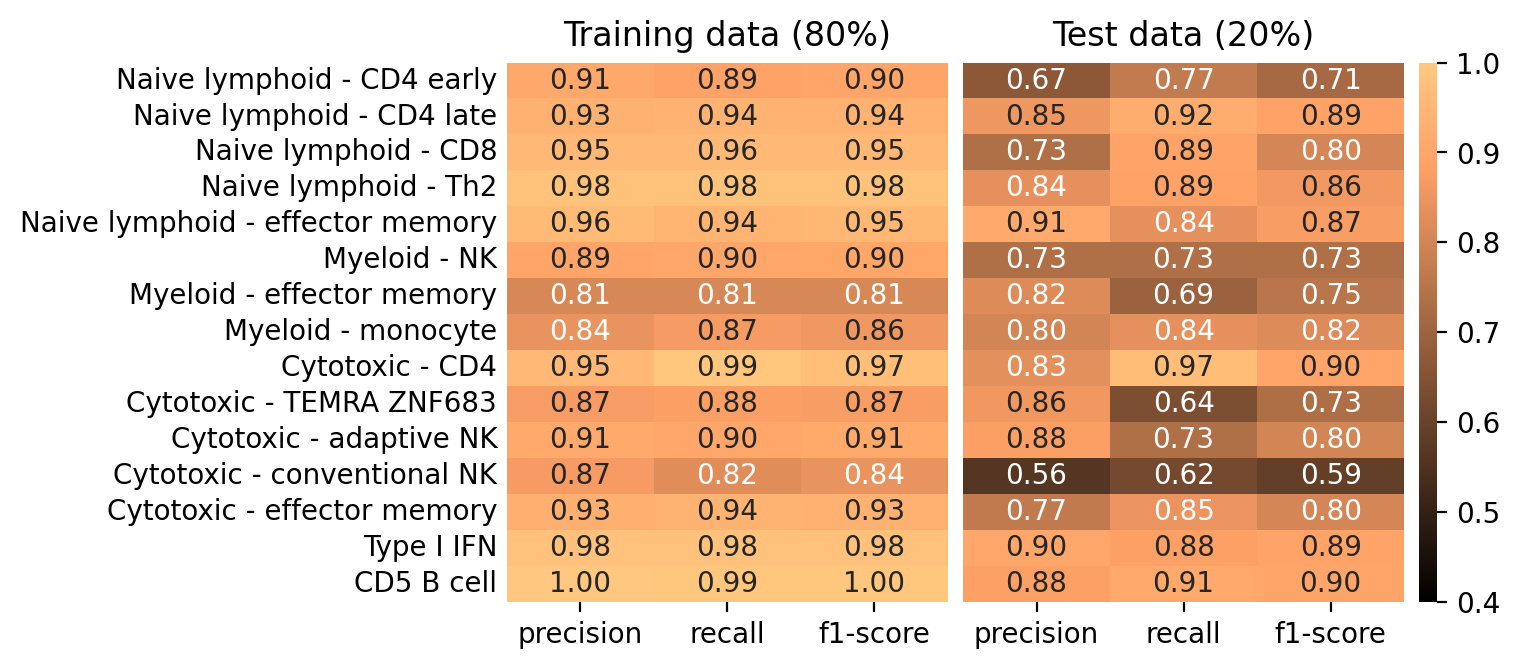

In [30]:
plot_classification_reports(
    y_true_train, y_pred_train,
    y_true_test, y_pred_test,
    title1="Training data (80%)",
    title2="Test data (20%)",
    cmap="copper",
    figsize=(6,3.5),
    vmin=0.4,
    vmax=1
)

We see from the test metrics that performance is somewhat lower than in training data, giving a realistic estimate of Some composition clusters, such as "Cytotoxic - conventional NK" show lower performance, potentially indicating a less clearly distinct cell composition profile in this cluster.